# Exercise 2: Face Recognition with DeepFace
DATA 78000, Computer Vision assignment


**Question:** *Does the same stock-photo model appear across several of the 1,797 flag photos?* Stock agencies shoot in series, so the same person is often photographed many times with different flags.

1. Uses real data instead of LFW: the **1,260 faces found in Exercise 1**, cropped from the original photos using the Exercise 1 bounding boxes.
2. Moves from one-reference-vs-ten to **all-vs-all**: every face is compared with every face in other images.
3. Groups matches into **clusters of recurring models**.
4. **Checks the model against hand labels.** A sample of pairs was labelled "same / different person" by eye, which lets us measure how often each threshold is right, and compare three DeepFace models (VGG-Face, the starter's default; Facenet512; ArcFace).
5. **Tests a specific weakness:** does recognition get worse as the head turns away from the camera? This uses the yaw values from Exercise 1.

Outputs (in `computer-vision/outputs/`):
- `ex2_embeddings_<model>.npy`: cached embeddings
- `ex2_pairs_to_label.csv`: the sampled pairs and their distances
- `ex2_clusters.csv`: recurring-model clusters
- `ex2_pair_scores.csv`: labelled pairs with every model's distance

## 1. Setup

In [1]:
import math
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from deepface import DeepFace
from deepface.modules.verification import find_threshold

warnings.filterwarnings("ignore")

# Find the course folder by walking up until we reach the folder that contains DATA7800_YOLO.
# This works whether the notebook lives in computer-vision/ or computer-vision/assignment/.
PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "DATA7800_YOLO").exists())
DATA_DIR = PROJECT_DIR / "DATA7800_YOLO"
CV_DIR = PROJECT_DIR / "computer-vision"
OUT_DIR = CV_DIR / "outputs"
ASSIGNMENT_DIR = CV_DIR / "assignment"

EX1_CSV = OUT_DIR / "ex1_faces.csv"                 # produced by ex1_mediapipe_faces.ipynb
LABELS_CSV = ASSIGNMENT_DIR / "ex2_pair_labels.csv"  # hand labels: same person or not

MODELS = ["VGG-Face", "Facenet512", "ArcFace"]      # VGG-Face is the starter's default
MAIN_MODEL = "Facenet512"                           # used for all-vs-all matching and clusters
CROP_PAD = 0.2                                      # pad the Exercise 1 face box by 20% before embedding

# DeepFace's own published cosine-DISTANCE thresholds (distance = 1 - similarity).
THRESHOLDS = {m: find_threshold(m, "cosine") for m in MODELS}
print("Cosine distance thresholds:", THRESHOLDS)
print("The starter's similarity threshold of 0.375 corresponds to a distance of", 1 - 0.375)

Cosine distance thresholds: {'VGG-Face': 0.68, 'Facenet512': 0.3, 'ArcFace': 0.68}
The starter's similarity threshold of 0.375 corresponds to a distance of 0.625


## 2. The canonical pattern, briefly
The starter's core idea in three lines: embed two faces, then compare the vectors with cosine similarity. We keep its definition of cosine similarity, and use **cosine distance = 1 − similarity** from here on, because that is what DeepFace's thresholds are written in. Lower distance means more alike.

In [2]:
def cosine_similarity(a, b):
    # Dot product divided by the product of the vector lengths (the starter's formula)
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))


def cosine_distance_matrix(emb):
    # All-vs-all version: normalise each row to length 1, then one matrix product gives every similarity
    unit = emb / np.linalg.norm(emb, axis=1, keepdims=True)
    return 1.0 - unit @ unit.T

## 3. Load the faces from Exercise 1 and crop them
Exercise 1 already saved padded crops, but its 50% padding includes a lot of hair and background. Here we re-crop from the original photo with a tighter 20% pad. Since we already know where the face is, we skip DeepFace's own detector (`detector_backend="skip"`).

In [3]:
ex1 = pd.read_csv(EX1_CSV)
faces = ex1[ex1.face_idx.notna()].reset_index(drop=True)
faces["face_key"] = faces.image_id.astype(str) + "_face" + faces.face_idx.astype(int).astype(str)
print(f"{len(faces)} faces from {faces.image_path.nunique()} images")


def crop_face(row, pad=CROP_PAD):
    img = cv2.imread(str(DATA_DIR / row.image_path))
    h, w = img.shape[:2]
    bw, bh = row.x2 - row.x1, row.y2 - row.y1
    x1, y1 = int(max(0, row.x1 - bw * pad)), int(max(0, row.y1 - bh * pad))
    x2, y2 = int(min(w, row.x2 + bw * pad)), int(min(h, row.y2 + bh * pad))
    return img[y1:y2, x1:x2]          # BGR, which is what DeepFace expects for numpy input


crops = [crop_face(r) for r in faces.itertuples()]

1260 faces from 1227 images


## 4. Embed every face with three models
`DeepFace.represent` turns each face into a vector: 4,096 numbers for VGG-Face, 512 for Facenet512 and ArcFace. Embeddings are cached to disk because this is the slow step (a few minutes per model on a CPU).

In [4]:
def embed_all(model_name):
    cache = OUT_DIR / f"ex2_embeddings_{model_name}.npy"
    if cache.exists():
        emb = np.load(cache)
        if len(emb) == len(crops):
            return emb
    vectors = []
    for i, crop in enumerate(crops):
        rep = DeepFace.represent(crop, model_name=model_name, detector_backend="skip", enforce_detection=False)
        vectors.append(rep[0]["embedding"])
        if (i + 1) % 300 == 0:
            print(f"  {model_name}: {i + 1}/{len(crops)}")
    emb = np.array(vectors, dtype=np.float32)
    np.save(cache, emb)
    return emb


embeddings = {}
for m in MODELS:
    embeddings[m] = embed_all(m)
    print(f"{m}: {embeddings[m].shape}")

distances = {m: cosine_distance_matrix(e) for m, e in embeddings.items()}

# Faces in the SAME photo are almost always different people, and we want cross-photo matches,
# so mask out same-image pairs (and each face against itself).
same_image = faces.image_path.values[:, None] == faces.image_path.values[None, :]
for m in MODELS:
    distances[m][same_image] = np.nan

26-11-22 21:37:47 - 🔗 vgg_face_weights.onnx will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.onnx to C:\Users\richa\.deepface\weights\vgg_face_weights.onnx...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/vgg_face_weights.onnx
To: C:\Users\richa\.deepface\weights\vgg_face_weights.onnx
100%|██████████| 537M/537M [00:30<00:00, 17.8MB/s] 


  VGG-Face: 300/1260
  VGG-Face: 600/1260
  VGG-Face: 900/1260
  VGG-Face: 1200/1260
VGG-Face: (1260, 4096)
26-11-22 21:56:17 - 🔗 facenet512_weights.onnx will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facenet512_weights.onnx to C:\Users\richa\.deepface\weights\facenet512_weights.onnx...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facenet512_weights.onnx
To: C:\Users\richa\.deepface\weights\facenet512_weights.onnx
100%|██████████| 94.0M/94.0M [00:02<00:00, 31.5MB/s]


  Facenet512: 300/1260
  Facenet512: 600/1260
  Facenet512: 900/1260
  Facenet512: 1200/1260
Facenet512: (1260, 512)
26-11-22 22:02:27 - 🔗 arcface_weights.onnx will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.onnx to C:\Users\richa\.deepface\weights\arcface_weights.onnx...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/arcface_weights.onnx
To: C:\Users\richa\.deepface\weights\arcface_weights.onnx
100%|██████████| 137M/137M [00:04<00:00, 28.7MB/s] 


  ArcFace: 300/1260
  ArcFace: 600/1260
  ArcFace: 900/1260
  ArcFace: 1200/1260
ArcFace: (1260, 512)


## 5. All-vs-all: who is each face's closest match in another photo?
For each face we find its nearest neighbour under Facenet512. If that distance is below DeepFace's threshold, the model claims the same person appears in another photo.

Faces whose closest match is under the Facenet512 threshold (0.3): 1027 of 1260 (82%)


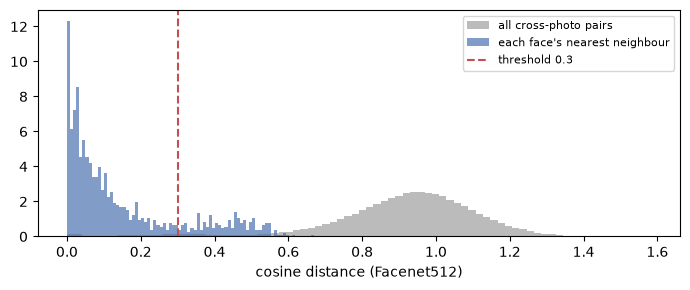

In [5]:
D = distances[MAIN_MODEL]
T = THRESHOLDS[MAIN_MODEL]
nn_idx = np.nanargmin(D, axis=1)
nn_dist = D[np.arange(len(D)), nn_idx]
faces["nn_face"] = faces.face_key.values[nn_idx]
faces["nn_dist"] = nn_dist.round(4)

print(f"Faces whose closest match is under the {MAIN_MODEL} threshold ({T}): "
      f"{(nn_dist < T).sum()} of {len(faces)} ({(nn_dist < T).mean():.0%})")

plt.figure(figsize=(7, 3))
plt.hist(D[np.triu_indices_from(D, 1)][~np.isnan(D[np.triu_indices_from(D, 1)])], bins=80,
         color="#bbbbbb", density=True, label="all cross-photo pairs")
plt.hist(nn_dist, bins=80, color="#4C72B0", alpha=0.7, density=True, label="each face's nearest neighbour")
plt.axvline(T, color="#C44E52", ls="--", label=f"threshold {T}")
plt.xlabel(f"cosine distance ({MAIN_MODEL})"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Clusters of recurring models
If face A matches B, and B matches C, all three go in one cluster ("connected components"). This is a simple form of the clustering from the data-clustering module. One weakness: a single false match can merge two different people into one cluster. So we use a **stricter** cut-off than the threshold here, and look at the results by eye.

In [6]:
CLUSTER_CUTOFF = 0.75 * T   # stricter than the verification threshold, to limit chain-merging


def connected_components(adj):
    # Plain breadth-first search: returns a cluster id for every node
    labels, current = -np.ones(len(adj), dtype=int), 0
    for start in range(len(adj)):
        if labels[start] >= 0:
            continue
        queue, labels[start] = [start], current
        while queue:
            node = queue.pop()
            for nb in np.where(adj[node] & (labels < 0))[0]:
                labels[nb] = current
                queue.append(nb)
        current += 1
    return labels


adjacency = np.nan_to_num(D, nan=9) < CLUSTER_CUTOFF
faces["cluster"] = connected_components(adjacency)
sizes = faces.cluster.value_counts()
faces["cluster_size"] = faces.cluster.map(sizes)
multi = sizes[sizes > 1]
print(f"{len(multi)} clusters with 2+ faces, covering {multi.sum()} faces; largest has {multi.max()} faces")
print("Cluster size distribution:", multi.value_counts().sort_index().to_dict())

faces[["face_key", "image_path", "yaw", "pitch", "nn_face", "nn_dist", "cluster", "cluster_size"]] \
    .sort_values(["cluster_size", "cluster"], ascending=[False, True]) \
    .to_csv(OUT_DIR / "ex2_clusters.csv", index=False)

164 clusters with 2+ faces, covering 966 faces; largest has 235 faces
Cluster size distribution: {2: 74, 3: 31, 4: 22, 5: 8, 6: 7, 7: 6, 8: 3, 10: 2, 11: 3, 13: 1, 14: 2, 20: 1, 21: 1, 23: 1, 96: 1, 235: 1}


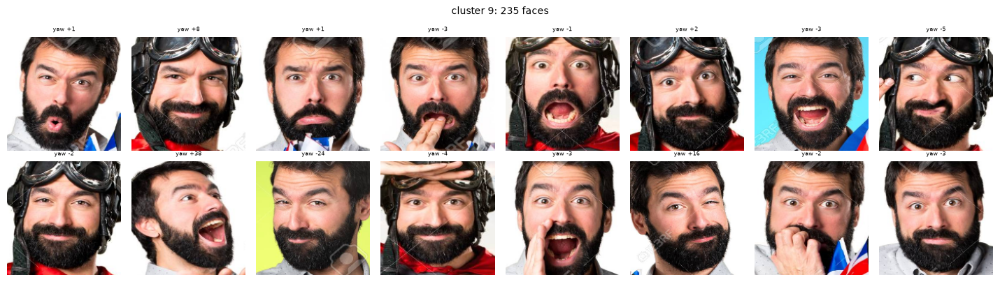

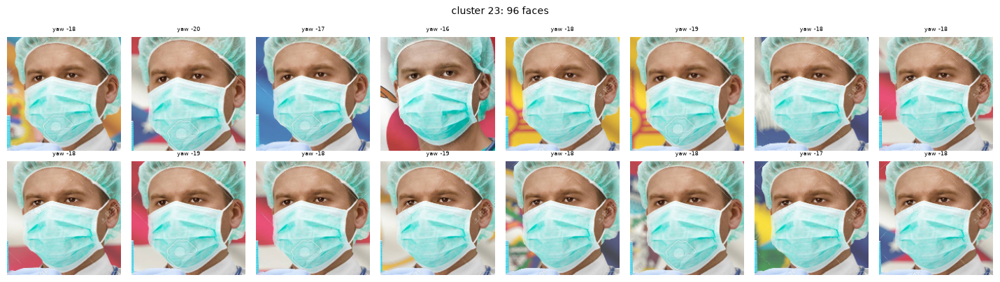

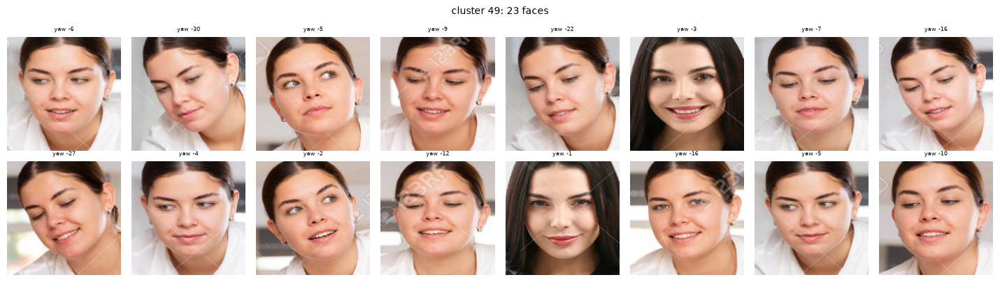

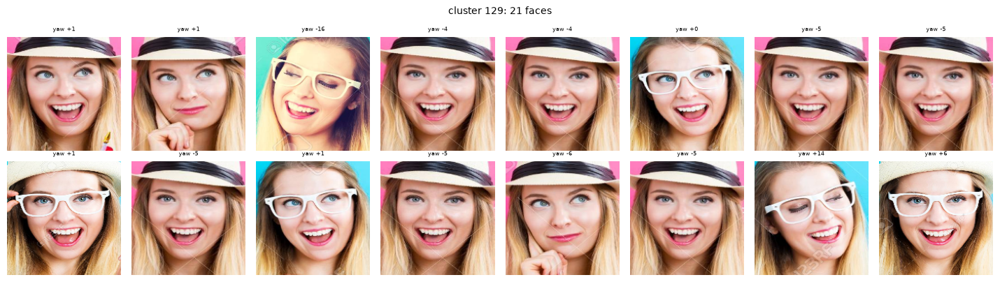

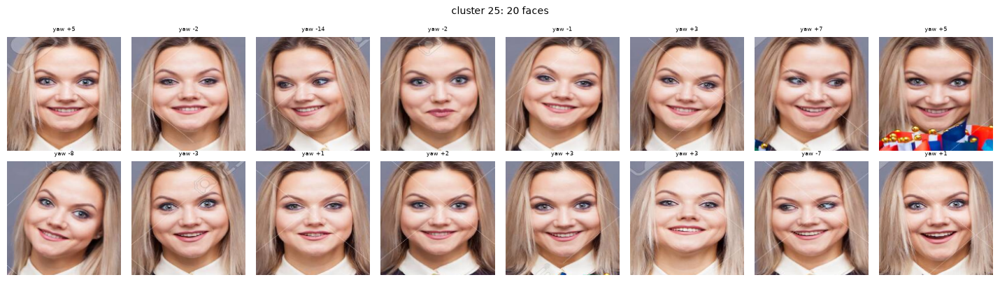

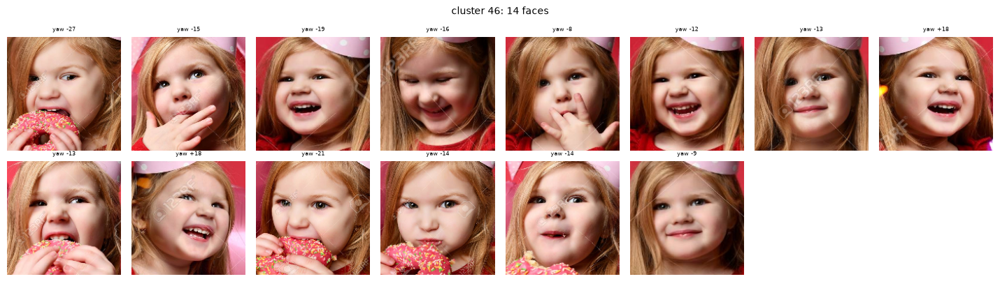

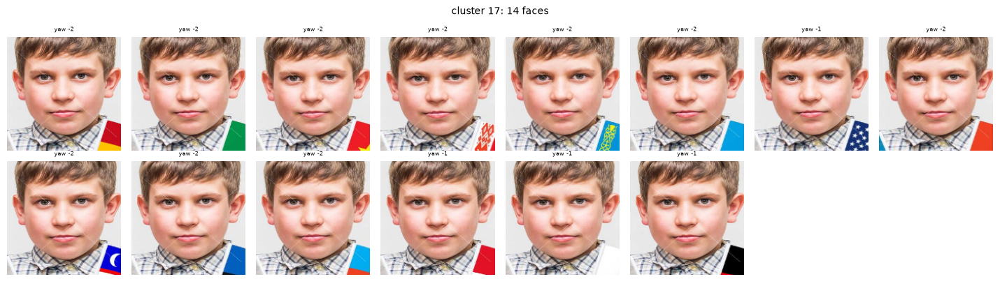

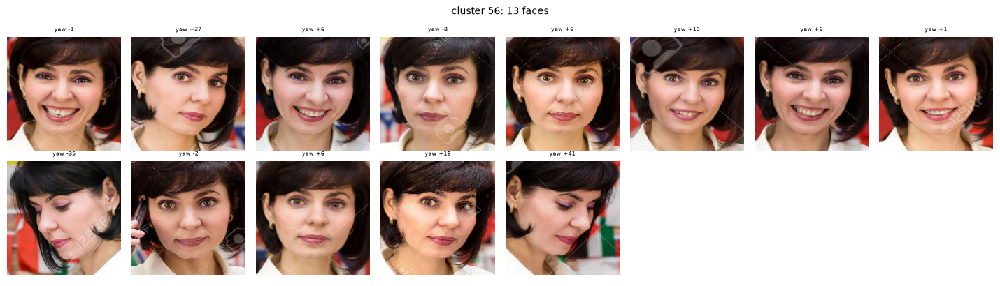

In [7]:
def show_faces(indices, titles=None, cols=8, size=1.8, suptitle=None):
    indices = list(indices)
    rows = math.ceil(len(indices) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size * 1.15))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for k, (ax, i) in enumerate(zip(np.atleast_1d(axes).ravel(), indices)):
        ax.imshow(cv2.cvtColor(cv2.resize(crops[i], (160, 160)), cv2.COLOR_BGR2RGB))
        ax.set_title(titles[k] if titles else faces.face_key[i], fontsize=6)
    if suptitle:
        fig.suptitle(suptitle, fontsize=10)
    plt.tight_layout()
    plt.show()


for cid in multi.index[:8]:
    members = faces.index[faces.cluster == cid][:16]
    show_faces(members, [f"yaw {faces.yaw[i]:+.0f}" for i in members],
               suptitle=f"cluster {cid}: {sizes[cid]} faces")

## 7. Ground truth: hand-labelled pairs
Clusters *look* convincing, but the only way to measure accuracy is to compare against human judgement. We sample pairs across the whole distance range: very close, around the threshold, and clearly far apart. Each pair was then labelled by eye in `assignment/ex2_pair_labels.csv` (`same_person` = 1 or 0). If a pair is unclear, it is marked as unsure and left out.

The sampling uses a fixed random seed, so the same pairs come out every time.

In [8]:
rng = np.random.default_rng(78000)
iu = np.triu_indices(len(D), 1)
pair_d = D[iu]
valid = ~np.isnan(pair_d)
pi, pj, pd_ = iu[0][valid], iu[1][valid], pair_d[valid]

# Distance bands relative to the threshold, with a fixed number of pairs from each
bands = [(0, 0.5 * T, 15), (0.5 * T, 0.8 * T, 15), (0.8 * T, 1.0 * T, 20),
         (1.0 * T, 1.25 * T, 20), (1.25 * T, 1.6 * T, 15), (1.6 * T, 9, 10)]
sample = []
for lo, hi, n in bands:
    idx = np.where((pd_ >= lo) & (pd_ < hi))[0]
    for k in rng.choice(idx, size=min(n, len(idx)), replace=False):
        sample.append((pi[k], pj[k]))

pairs = pd.DataFrame(sample, columns=["i", "j"])
pairs["face_a"] = faces.face_key.values[pairs.i]
pairs["face_b"] = faces.face_key.values[pairs.j]
for m in MODELS:
    pairs[f"dist_{m}"] = [round(float(distances[m][i, j]), 4) for i, j in zip(pairs.i, pairs.j)]
pairs["abs_yaw_diff"] = (faces.yaw.values[pairs.i] - faces.yaw.values[pairs.j]).__abs__().round(1)
pairs["max_abs_yaw"] = np.maximum(faces.yaw.abs().values[pairs.i], faces.yaw.abs().values[pairs.j]).round(1)
pairs = pairs.sort_values(f"dist_{MAIN_MODEL}").reset_index(drop=True)
pairs.to_csv(OUT_DIR / "ex2_pairs_to_label.csv", index=False)
print(f"{len(pairs)} pairs sampled")

95 pairs sampled


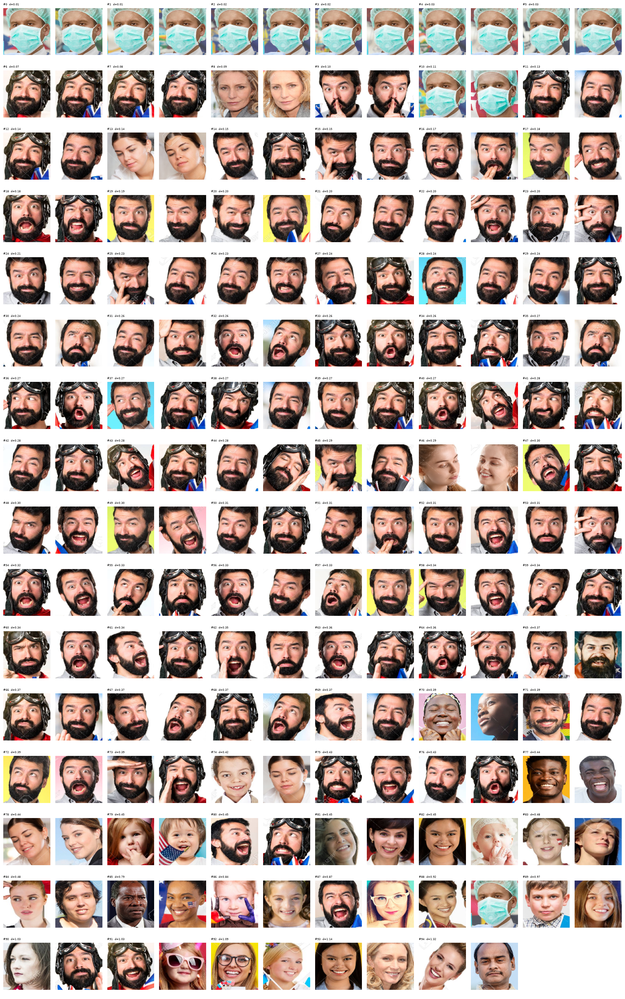

In [9]:
# Pair sheet used for labelling: each pair side by side, with its Facenet512 distance
def show_pairs(df, cols=6, size=1.6):
    rows = math.ceil(len(df) / cols)
    fig, axes = plt.subplots(rows, cols * 2, figsize=(cols * 2 * size, rows * size * 1.2))
    for ax in axes.ravel():
        ax.axis("off")
    for k, r in enumerate(df.itertuples()):
        a, b = axes.ravel()[2 * k], axes.ravel()[2 * k + 1]
        a.imshow(cv2.cvtColor(cv2.resize(crops[r.i], (120, 120)), cv2.COLOR_BGR2RGB))
        b.imshow(cv2.cvtColor(cv2.resize(crops[r.j], (120, 120)), cv2.COLOR_BGR2RGB))
        a.set_title(f"#{r.Index}  d={getattr(r, 'dist_' + MAIN_MODEL.replace('-', '_'), 0):.2f}", fontsize=6, loc="left")
    plt.tight_layout()
    plt.show()


show_pairs(pairs)

## 8. How accurate is each model?
We join the hand labels and check, for each model, how often "distance < DeepFace threshold" agrees with the human label. We also ask which threshold *would* have been best on this data. Expect that number to be optimistic: it is fitted to the same pairs it is scored on.

In [10]:
if not LABELS_CSV.exists():
    # First run: write a template to fill in by eye (1 = same person, 0 = different, blank = unsure)
    pairs[["face_a", "face_b"]].assign(same_person="", note="").to_csv(LABELS_CSV, index=False)
    raise SystemExit(f"Wrote a labelling template to {LABELS_CSV}. Fill in same_person and re-run.")

labels = pd.read_csv(LABELS_CSV)
scored = pairs.merge(labels[["face_a", "face_b", "same_person", "note"]], on=["face_a", "face_b"], how="left")
scored = scored[scored.same_person.isin([0, 1])].copy()
scored.to_csv(OUT_DIR / "ex2_pair_scores.csv", index=False)
print(f"{len(scored)} labelled pairs: {int(scored.same_person.sum())} same person, "
      f"{int((1 - scored.same_person).sum())} different")


def evaluate(d, y, t):
    pred = (d < t).astype(int)
    tp, tn = ((pred == 1) & (y == 1)).sum(), ((pred == 0) & (y == 0)).sum()
    fp, fn = ((pred == 1) & (y == 0)).sum(), ((pred == 0) & (y == 1)).sum()
    return {"accuracy": (tp + tn) / len(y), "false_matches": fp, "missed_matches": fn}


rows = []
for m in MODELS:
    d, y = scored[f"dist_{m}"].values, scored.same_person.values
    default = evaluate(d, y, THRESHOLDS[m])
    candidates = np.unique(d)
    best_t = max(candidates, key=lambda t: evaluate(d, y, t)["accuracy"])
    best = evaluate(d, y, best_t)
    rows.append({"model": m, "deepface_threshold": THRESHOLDS[m], **default,
                 "best_threshold_here": round(float(best_t), 3), "best_accuracy_here": best["accuracy"]})
results = pd.DataFrame(rows)
results.round(3)

94 labelled pairs: 73 same person, 21 different


,model,deepface_threshold,accuracy,false_matches,missed_matches,best_threshold_here,best_accuracy_here
0,VGG-Face,0.68,0.915,3,5,0.731,0.926
1,Facenet512,0.30,0.745,0,24,0.435,0.947
2,ArcFace,0.68,0.798,7,12,0.669,0.819


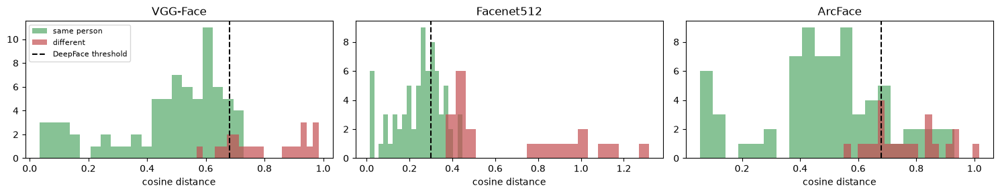

In [11]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 3))
for ax, m in zip(axes, MODELS):
    for label, colour, name in [(1, "#55A868", "same person"), (0, "#C44E52", "different")]:
        ax.hist(scored.loc[scored.same_person == label, f"dist_{m}"], bins=20, alpha=0.7, color=colour, label=name)
    ax.axvline(THRESHOLDS[m], color="k", ls="--", label="DeepFace threshold")
    ax.set_title(m); ax.set_xlabel("cosine distance")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Does head pose hurt recognition?
For the **same-person** pairs, we plot distance against the difference in yaw between the two faces (from Exercise 1). If the model were pose-invariant, the points would be flat. A rising trend means a turned head makes the same person look like a stranger to the model.

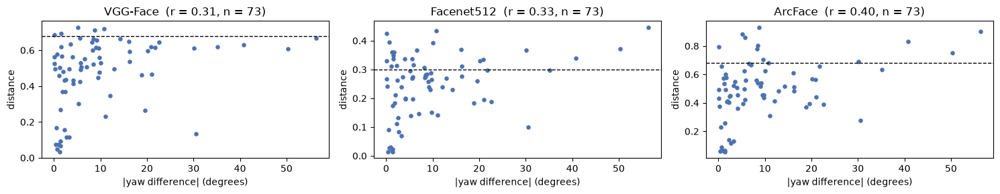

In [12]:
same = scored[scored.same_person == 1]
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 3))
for ax, m in zip(axes, MODELS):
    ax.scatter(same.abs_yaw_diff, same[f"dist_{m}"], s=14, color="#4C72B0")
    ax.axhline(THRESHOLDS[m], color="k", ls="--", lw=1)
    r = np.corrcoef(same.abs_yaw_diff, same[f"dist_{m}"])[0, 1] if len(same) > 2 else float("nan")
    ax.set_title(f"{m}  (r = {r:.2f}, n = {len(same)})")
    ax.set_xlabel("|yaw difference| (degrees)"); ax.set_ylabel("distance")
plt.tight_layout()
plt.show()

## 10. The failures, up close
The worst mistakes of the main model: different people it called a match, and same-person pairs it missed.

FALSE MATCHES (different people, distance under threshold): 0
MISSED MATCHES (same person, distance over threshold): 24


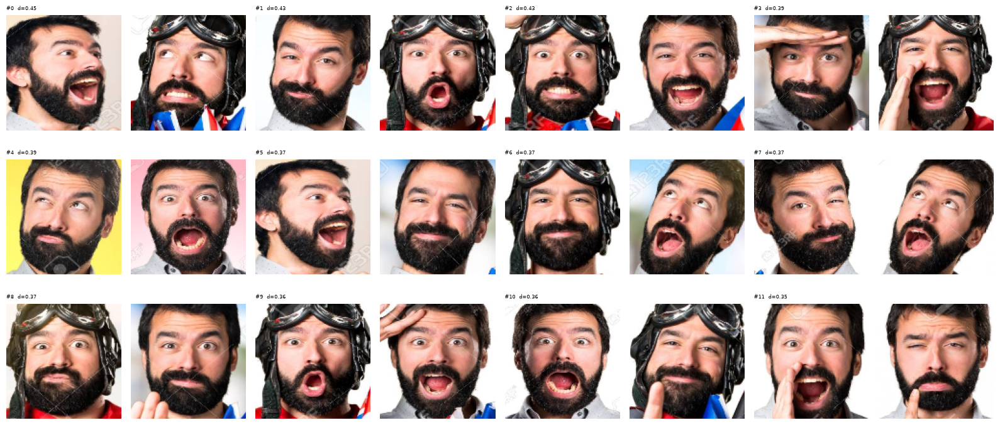

In [13]:
col = f"dist_{MAIN_MODEL}"
false_matches = scored[(scored.same_person == 0) & (scored[col] < T)].sort_values(col)
missed = scored[(scored.same_person == 1) & (scored[col] >= T)].sort_values(col, ascending=False)
for name, df in [("FALSE MATCHES (different people, distance under threshold)", false_matches),
                 ("MISSED MATCHES (same person, distance over threshold)", missed)]:
    print(f"{name}: {len(df)}")
    if len(df):
        show_pairs(df.head(12).reset_index(drop=True), cols=4, size=2)

## 11. Reflection

- **The collection repeats the same few people.** One bearded man (also the "pilot" and "superhero") is 235 of 1,260 faces, about 19%. Some clusters are literally the same photo pasted onto different flags, such as the boy and the masked doctor.
- **Accuracy at each model's default threshold:**

  | Model | Accuracy | False matches | Missed matches |
  |---|---|---|---|
  | VGG-Face | 92% | 3 | 5 |
  | Facenet512 | 75% | 0 | 24 |
  | ArcFace | 80% | 7 | 12 |

  Facenet512 never wrongly matched two different people, but its threshold is too strict for this data. It missed 24 same-person pairs, mostly very expressive faces.
- **Head turn hurts only a little** (correlation about 0.3–0.4). Expressions like a wide-open mouth or rolled eyes caused more misses than head angle.

